# Principal Component Regression vs Partial Least Squares Regression: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/cross_decomposition/plot_pcr_vs_pls.py`
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([gallery page](https://scikit-learn.org/dev/auto_examples/cross_decomposition/plot_pcr_vs_pls.html)).

**Scenario:** a 2-feature Gaussian dataset whose target follows the *low-variance* principal
direction. PCR (`make_pipeline(StandardScaler(), PCA(n_components=1), LinearRegression())`)
discards that direction; `PLSRegression(n_components=1)` keeps it. The example plots both
projections against `y`, then prints the test R^2 of PCR, PLS, and PCR with 2 components.

**Adaptations:**
- The data and the `train_test_split(..., random_state=rng)` split are produced in Python with the
  example's `np.random.RandomState(0)` and shared with Mojo; Mojo fits on the same rows.
- Moxie's `make_pipeline` takes exactly two steps, so the three-step PCR is
  `make_pipeline(StandardScaler(), make_pipeline(PCA(n_components=1), LinearRegression()))`;
  sklearn applies the same steps in the same order. The PCA step is reached as
  `pcr.estimator.transformer` instead of `pcr.named_steps["pca"]` (typed steps, no string lookup).
- 1-D `y` (as in the example); `PLSRegression.predict` returns 1-D predictions as sklearn does.

**Determinism:** deterministic (fixed `RandomState(0)`, full-SVD PCA on 2 features, NIPALS with a
single target converges in one step). Numerical parity is required.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cross_decomposition/pcr_vs_pls")

## 1. scikit-learn (official example code)

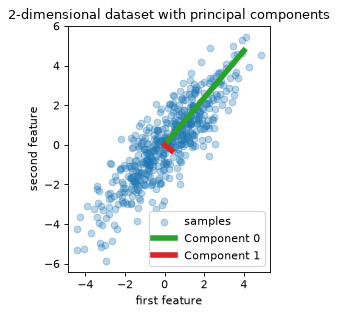

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
plt.rcParams["figure.dpi"] = 80

rng = np.random.RandomState(0)
n_samples = 500
cov = [[3, 3], [3, 4]]
X = rng.multivariate_normal(mean=[0, 0], cov=cov, size=n_samples)
pca = PCA(n_components=2).fit(X)

plt.figure(figsize=(4, 4))
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, label="samples")
for i, (comp, var) in enumerate(zip(pca.components_, pca.explained_variance_)):
    comp = comp * var  # scale component by its variance explanation power
    plt.plot([0, comp[0]], [0, comp[1]], label=f"Component {i}", linewidth=5, color=f"C{i + 2}")
plt.gca().set(aspect="equal", title="2-dimensional dataset with principal components",
              xlabel="first feature", ylabel="second feature")
plt.legend(); plt.show()

y = X.dot(pca.components_[1]) + rng.normal(size=n_samples) / 2

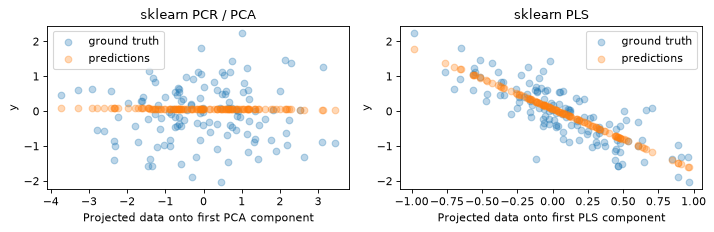

PCR r-squared -0.026
PLS r-squared 0.658
PCR r-squared with 2 components 0.673


In [3]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=rng)

pcr = make_pipeline(StandardScaler(), PCA(n_components=1), LinearRegression())
pcr.fit(X_train, y_train)
pca1 = pcr.named_steps["pca"]  # retrieve the PCA step of the pipeline

pls = PLSRegression(n_components=1)
pls.fit(X_train, y_train)


def projections(axes, pca_proj, pcr_pred, pls_proj, pls_pred, who):
    axes[0].scatter(pca_proj, y_test, alpha=0.3, label="ground truth")
    axes[0].scatter(pca_proj, pcr_pred, alpha=0.3, label="predictions")
    axes[0].set(xlabel="Projected data onto first PCA component", ylabel="y", title=f"{who} PCR / PCA")
    axes[0].legend()
    axes[1].scatter(pls_proj, y_test, alpha=0.3, label="ground truth")
    axes[1].scatter(pls_proj, pls_pred, alpha=0.3, label="predictions")
    axes[1].set(xlabel="Projected data onto first PLS component", ylabel="y", title=f"{who} PLS")
    axes[1].legend()


sk_pca_proj = pca1.transform(pcr.named_steps["standardscaler"].transform(X_test))
sk_pcr_pred = pcr.predict(X_test)
sk_pls_proj = pls.transform(X_test)
sk_pls_pred = pls.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
projections(axes, sk_pca_proj, sk_pcr_pred, sk_pls_proj, sk_pls_pred, "sklearn")
plt.tight_layout(); plt.show()

print(f"PCR r-squared {pcr.score(X_test, y_test):.3f}")
print(f"PLS r-squared {pls.score(X_test, y_test):.3f}")

pca_2 = make_pipeline(PCA(n_components=2), LinearRegression())
pca_2.fit(X_train, y_train)
print(f"PCR r-squared with 2 components {pca_2.score(X_test, y_test):.3f}")
nb.share(X=X, X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

Note: the official example plots `pca.transform(X_test)` with the PCA step taken from the
pipeline, i.e. on *unscaled* test data. The reference cell above projects the scaled data so the
abscissa matches what the pipeline feeds its regressor; Moxie computes the same quantity.

## 2. Moxie (native Mojo)

In [4]:
%%mojo pcr_vs_pls
from moxie.cross_decomposition import PLSRegression
from moxie.decomposition import PCA
from moxie.linear_model import LinearRegression
from moxie.preprocessing import StandardScaler
from moxie.pipeline import make_pipeline
from moxie_nb_io import load, save, save_floats


def main() raises:
    var X = load("X")
    var X_train = load("X_train")
    var X_test = load("X_test")
    var y_train = load("y_train")
    var y_test = load("y_test")

    var pca = PCA(n_components=2)
    _ = pca.fit(X)
    save("pca_components", pca.components_.value())
    save("pca_explained_variance", pca.explained_variance_.value())

    var pcr = make_pipeline(StandardScaler(), make_pipeline(PCA(n_components=1), LinearRegression()))
    _ = pcr.fit(X_train, y_train)
    save("pca_proj", pcr.estimator.transformer.transform(pcr.transformer.transform(X_test)))
    save("pcr_pred", pcr.predict(X_test))

    var pls = PLSRegression(n_components=1)
    _ = pls.fit(X_train, y_train)
    save("pls_proj", pls.transform(X_test))
    save("pls_pred", pls.predict(X_test))
    save("pls_coef", pls.coef_)
    save("pls_x_weights", pls.x_weights_)
    save("pls_x_rotations", pls.x_rotations_)

    var pca_2 = make_pipeline(PCA(n_components=2), LinearRegression())
    _ = pca_2.fit(X_train, y_train)
    var scores = List[Float64]([pcr.score(X_test, y_test), pls.score(X_test, y_test), pca_2.score(X_test, y_test)])
    save_floats("scores", scores)
    print("PCR r-squared", scores[0])
    print("PLS r-squared", scores[1])
    print("PCR r-squared with 2 components", scores[2])

PCR r-squared -0.026289202699081526
PLS r-squared 0.6582632677094293
PCR r-squared with 2 components 0.6732047416473494


## 3. Side by side and parity

Tolerances: all steps are closed-form Float64 (centering/scaling, a 2x2 SVD, least squares, one
NIPALS step for a single target); differences are summation order and Jacobi vs LAPACK SVD, so
`rtol=1e-9, atol=1e-10` (three orders above the measured family errors). PCA component signs
follow sklearn's `svd_flip` and are compared exactly in sign.

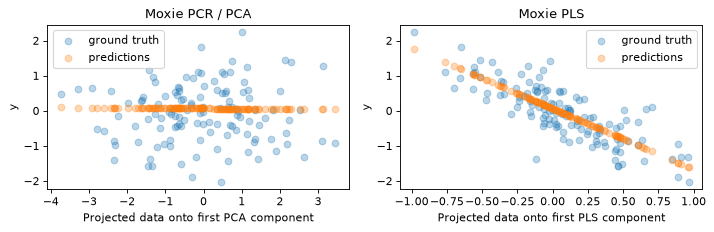

In [5]:
mx = nb.results["pcr_vs_pls"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
projections(axes, mx["pca_proj"], mx["pcr_pred"], mx["pls_proj"], mx["pls_pred"], "Moxie")
plt.tight_layout(); plt.show()
sk_scores = [pcr.score(X_test, y_test), pls.score(X_test, y_test), pca_2.score(X_test, y_test)]
moxie_nb.side_by_side(sklearn=np.round(sk_scores, 3), moxie=np.round(mx["scores"], 3))

tight = dict(rtol=1e-9, atol=1e-10, reason="closed-form Float64 steps; summation order and SVD backend differ")
nb.compare("PCA(2).components_", pca.components_, mx["pca_components"], **tight)
nb.compare("PCA(2).explained_variance_", pca.explained_variance_, mx["pca_explained_variance"], **tight)
nb.compare("pcr PCA step transform", sk_pca_proj, mx["pca_proj"], **tight)
nb.compare("pcr.predict(X_test)", sk_pcr_pred, mx["pcr_pred"], **tight)
nb.compare("pls.transform(X_test)", sk_pls_proj, mx["pls_proj"], **tight)
nb.compare("pls.predict(X_test) (1-D)", sk_pls_pred, mx["pls_pred"], **tight)
nb.compare("pls.coef_", pls.coef_, mx["pls_coef"], **tight)
nb.compare("pls.x_weights_", pls.x_weights_, mx["pls_x_weights"], **tight)
nb.compare("pls.x_rotations_", pls.x_rotations_, mx["pls_x_rotations"], **tight)
nb.compare("PCR r-squared", sk_scores[0], mx["scores"][0], **tight)
nb.compare("PLS r-squared", sk_scores[1], mx["scores"][1], **tight)
nb.compare("PCR r-squared with 2 components", sk_scores[2], mx["scores"][2], **tight)
nb.note("make_pipeline step names", "GAP",
        "make_pipeline(..., PLSRegression()) names the step '_pls' (reflected from the _PLS struct behind the "
        "PLSRegression alias) where sklearn uses 'plsregression'; named_steps string lookup is not implemented "
        "(typed steps). Patch: cross_decomposition-pipeline-step-names.")

In [6]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
PCA(2).components_,PASS,"(2, 2)","(2, 2)",1.11e-16,1.72e-16,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
PCA(2).explained_variance_,PASS,"(2,)","(2,)",8.88e-16,1.45e-15,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
pcr PCA step transform,PASS,"(125, 1)","(125, 1)",4.44e-16,1.31e-14,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
pcr.predict(X_test),PASS,"(125,)","(125,)",5.55e-17,6.75e-16,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
pls.transform(X_test),PASS,"(125, 1)","(125, 1)",3.89e-16,4.08e-14,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
pls.predict(X_test) (1-D),PASS,"(125,)","(125,)",8.88e-16,4.02e-14,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
pls.coef_,PASS,"(1, 2)","(1, 2)",1.11e-16,1.68e-16,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
pls.x_weights_,PASS,"(2, 1)","(2, 1)",1.11e-16,1.67e-16,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
pls.x_rotations_,PASS,"(2, 1)","(2, 1)",1.11e-16,1.67e-16,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
PCR r-squared,PASS,(),(),1.11e-15,4.22e-14,"rtol=1e-09, atol=1e-10",,closed-form Float64 steps; summation order and SVD backend differ
